---
title: "Лекція 7. Causal Machine Learning як інструментарій дослідження гетерогенних причинних ефектів"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


## Мета лекції

Сформувати системне розуміння *причинного машинного навчання (Causal Machine Learning)* як інструментарію оцінювання середніх і гетерогенних причинних ефектів за складних залежностей у даних, з урахуванням припущень ідентифікації, контролю перенавчання, невизначеності та меж наукової інтерпретації.

## Очікувані результати навчання

Після лекції аспірант зможе:

1. Розрізняти прогноз $Y$, оцінювання середнього причинного ефекту (ATE) та умовного середнього причинного ефекту (CATE).
2. Пояснювати роль показника схильності (propensity score) і регресій потенційних результатів.
3. Виводити логіку зважування за оберненою ймовірністю та двічі стійкого оцінювання.
4. Порівнювати S-learner, T-learner, X-learner та причинні ліси.
5. Пояснювати ортогоналізацію, cross-fitting та Double/Debiased Machine Learning (DML).
6. Планувати аудит перекриття, якості nuisance-моделей, невизначеності та стабільності оцінок.

## План лекції

1. Від ідентифікації до оцінювання.
2. ATE, ATT і CATE: різні цільові параметри.
3. Propensity score та overlap.
4. IPW і двічі стійкий AIPW.
5. Мета-алгоритми для CATE.
6. Причинні ліси (causal forests).
7. Double/Debiased Machine Learning.
8. Обчислювальний експеримент: гетерогенний ефект.
9. Оцінювання невизначеності та валідація.
10. Дослідницький протокол і зв'язок із ЛР7.

Ключові джерела: [@hernan2020causal; @pearl2009causality; @peters2017elements; @hastie2009elements].

# 1. Від ідентифікації до оцінювання

У лекції 6 ми сформулювали причинне питання, DAG, набір коригування та припущення *консистентності, умовної обмінності й позитивності*. Лише після цього можна обирати алгоритм оцінювання.

Нехай $T\in\{0,1\}$ -- втручання, $Y$ -- результат, $X$ -- передвтручальні коваріати.

$$
Y(t)\perp T\mid X,\qquad 0<P(T=1\mid X=x)<1.
$$

За відповідних припущень:

$$
ATE=\mathbb{E}_X[\mu_1(X)-\mu_0(X)],
$$

де

$$
\mu_t(x)=\mathbb{E}[Y\mid T=t,X=x].
$$

*ML не робить причинний ефект ідентифікованим*: він може гнучко оцінювати функції, які вже з'явилися у формулі ідентифікації [@hernan2020causal].

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Причинне питання<br/>і DAG") --> B("Ідентифікація<br/>та припущення")
 B --> C("Nuisance-моделі:<br/>e(x), mu0(x), mu1(x)")
 C --> D("ATE / CATE<br/>оцінювання")
 D --> E("Overlap,<br/>невизначеність")
 E --> F("Обмежене<br/>наукове твердження")
```

# 2. ATE, ATT та CATE

*Середній причинний ефект (average treatment effect, ATE)*:

$$
ATE=\mathbb{E}[Y(1)-Y(0)].
$$

*Середній ефект серед тих, хто отримав втручання (average treatment effect on the treated, ATT)*:

$$
ATT=\mathbb{E}[Y(1)-Y(0)\mid T=1].
$$

*Умовний середній причинний ефект (conditional average treatment effect, CATE)*:

$$
\tau(x)=\mathbb{E}[Y(1)-Y(0)\mid X=x].
$$

Важливо: CATE -- середній ефект *для підпопуляції з коваріатами $X=x$*, а не неспостережуваний індивідуальний ефект $Y_i(1)-Y_i(0)$.

## Ручний приклад гетерогенності

Нехай є дві підгрупи, $G=0$ та $G=1$, по 50% популяції. У першій CATE дорівнює 1, у другій -- 3. Тоді:

$$
ATE=0.5\cdot 1+0.5\cdot 3=2.
$$

Середній ефект 2 приховує неоднорідність. Для наукової інтерпретації необхідно розрізняти *гетерогенність ефекту* і *відмінності прогнозного ризику*.

# 3. Показник схильності та перекриття

*Показник схильності (propensity score)*:

$$
e(x)=P(T=1\mid X=x).
$$

Він описує механізм призначення втручання за виміряними коваріатами, а не причинний ефект. За умовної обмінності на $X$ показник схильності може використовуватися для балансування виміряних коваріат [@hernan2020causal].

*Позитивність (positivity)* вимагає, щоб для релевантних $x$ існувала ненульова ймовірність кожного рівня втручання. Якщо $e(x)$ наближається до 0 або 1, оцінки зі зважуванням можуть бути нестійкими.

# 4. Зважування та двічі стійке оцінювання

## 4.1. IPW

*Зважування за оберненою ймовірністю (inverse probability weighting, IPW)* для ATE:

$$
\widehat{ATE}_{IPW}=
\frac1n\sum_{i=1}^{n}
\left[
\frac{T_iY_i}{\hat e(X_i)}
-
\frac{(1-T_i)Y_i}{1-\hat e(X_i)}
\right].
$$

Цей оцінювач залежить від коректності моделі схильності; за екстремальних $\hat e$ ваги зростають.

## 4.2. AIPW

*Доповнене зважування за оберненою ймовірністю (augmented inverse probability weighting, AIPW)* поєднує оцінки результату $\hat\mu_t(x)$ і схильності $\hat e(x)$:

$$
\widehat{ATE}_{AIPW}
=
\frac1n\sum_{i=1}^{n}
\left[
\hat\mu_1(X_i)-\hat\mu_0(X_i)
+
\frac{T_i(Y_i-\hat\mu_1(X_i))}{\hat e(X_i)}
-
\frac{(1-T_i)(Y_i-\hat\mu_0(X_i))}{1-\hat e(X_i)}
\right].
$$

*Подвійна стійкість (double robustness)* означає, що за стандартних умов оцінка може залишатися консистентною, якщо правильно специфіковано принаймні одну з двох компонент: propensity або outcome regression. Це **не означає** стійкості до невиміряного змішування, відсутності overlap чи довільних помилок даних.

## Приклад AIPW для одного спостереження

Нехай $T=1$, $Y=5$, $\hat e=0.4$, $\hat\mu_1=4$, $\hat\mu_0=2$. Внесок цього спостереження в середнє:

$$
(4-2)+\frac{1(5-4)}{0.4}
-\frac{0(5-2)}{0.6}
=4.5.
$$

Це *один доданок* AIPW-оцінювача, а не оцінка ATE на одному спостереженні.

# 5. Мета-алгоритми для гетерогенних ефектів

*Мета-алгоритми (meta-learners)* використовують стандартні ML-регресори як компоненти оцінювання причинних ефектів.

| Метод | Ідея | Обмеження |
|---|---|---|
| S-learner | Одна модель $\hat m(X,T)$; $\hat\tau(x)=\hat m(x,1)-\hat m(x,0)$ | Модель може ігнорувати $T$ |
| T-learner | Окремі моделі $\hat\mu_1(x)$ і $\hat\mu_0(x)$ | Складно за малого розміру однієї групи |
| X-learner | Імпутація псевдоефектів і комбінування оцінок | Потрібна якісна модель потенційних результатів |
| R-learner | Регресія залишків після ортогоналізації | Чутливість до nuisance-оцінювання та overlap |

## T-learner: проста конструкція

$$
\hat\tau_T(x)=\hat\mu_1(x)-\hat\mu_0(x).
$$

Цей підхід легко реалізувати, але точність *кожного* прогнозу $\hat\mu_t$ ще не гарантує точності їх різниці. Потрібна окрема перевірка причинної постановки та стійкості CATE.

# 6. Причинні ліси

*Причинні ліси (causal forests)* узагальнюють ідею дерев та ансамблів для оцінювання гетерогенних причинних ефектів. На відміну від звичайного Random Forest, їхня мета -- не мінімізувати помилку прогнозу $Y$, а оцінювати відмінності потенційних результатів між підгрупами.

Принципи:

1. Побудова розбиттів, чутливих до відмінностей ефектів.
2. Відокремлення побудови структури від оцінювання ефекту (*honesty*) у відповідних реалізаціях.
3. Агрегація за ансамблем.
4. Оцінювання невизначеності за умовами конкретного методу.

*Звичайний RandomForestRegressor, навчений на $Y$, не стає causal forest лише тому, що містить ознаку $T$.*

# 7. Double/Debiased Machine Learning

*Подвійне/дебайасоване машинне навчання (Double/Debiased Machine Learning, DML)* використовує ортогональні моментні умови й *перехресне підставляння (cross-fitting)* для зменшення впливу похибок nuisance-моделей на оцінювання причинного параметра.

Для частково лінійної моделі:

$$
Y=\theta_0T+g_0(X)+\varepsilon,
\qquad
T=m_0(X)+\nu.
$$

Після оцінювання умовних середніх $\ell(X)=\mathbb{E}[Y\mid X]$ та $m(X)=\mathbb{E}[T\mid X]$:

$$
\tilde Y_i=Y_i-\hat\ell(X_i),
\qquad
\tilde T_i=T_i-\hat m(X_i).
$$

Оцінка коефіцієнта через залишки:

$$
\hat\theta=
\frac{\sum_i\tilde T_i\tilde Y_i}
{\sum_i\tilde T_i^2}.
$$

У *cross-fitting* nuisance-моделі для спостереження $i$ навчаються на інших фолдах. Це зменшує ризик використання перенавчених прогнозів для побудови моментної умови.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Дані") --> B("Розбиття<br/>на фолди")
 B --> C("Nuisance-моделі<br/>на інших фолдах")
 C --> D("Out-of-fold<br/>прогнози")
 D --> E("Ортогональний<br/>момент")
 E --> F("Ефект та<br/>невизначеність")
```

*Застереження:* наведений частково лінійний DML оцінює **скалярний параметр** за припущенням адитивного сталого ефекту в цій моделі. Для довільно гетерогенних ефектів потрібні інші параметризації й оцінювачі.

# 8. Навчальний експеримент: гетерогенний ефект

Згенеруємо контрольовані спостережувальні дані, де:

- $X_1$ впливає на схильність до втручання;
- $X_1$ і $X_2$ впливають на базовий результат;
- причинний ефект залежить від $X_1$.

Зафіксуємо генератор:

$$
e(x)=\sigma(-0.2+0.8x_1-0.4x_2),
$$

$$
Y(0)=1+1.5x_1-0.5x_2+0.5x_1^2+\varepsilon,
$$

$$
Y(1)=Y(0)+\tau(x),
\qquad
\tau(x)=1+0.8x_1.
$$

Оскільки $\mathbb{E}[X_1]=0$, теоретичний $ATE=1$. У реальному дослідженні істинні потенційні наслідки невідомі.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)
n = 2400
X = rng.normal(size=(n, 2))
x1, x2 = X[:, 0], X[:, 1]
sigmoid = lambda z: 1 / (1 + np.exp(-z))

e_true = sigmoid(-0.2 + 0.8*x1 - 0.4*x2)
T = rng.binomial(1, e_true)
tau_true = 1 + 0.8*x1
eps = rng.normal(scale=1, size=n)
Y0 = 1 + 1.5*x1 - 0.5*x2 + 0.5*x1**2 + eps
Y1 = Y0 + tau_true
Y = np.where(T == 1, Y1, Y0)

print("Реалізований ATE:", round(float(np.mean(tau_true)), 3))
print("Наївна різниця середніх:",
      round(float(Y[T==1].mean()-Y[T==0].mean()), 3))
print("Межі propensity:", np.round(np.quantile(e_true,[.01,.5,.99]),3))


Реалізований ATE: 0.982
Наївна різниця середніх: 2.56
Межі propensity: [0.101 0.445 0.872]


## 8.1. T-learner: дві моделі результату

Для кожного рівня втручання навчимо окремий регресор. У навчальному прикладі порівняємо CATE з відомою функцією генератора. Це *діагностика синтетичного експерименту*, недоступна в реальних даних.


T-learner ATE: 1.079
CATE RMSE (лише синтетичний контроль): 0.492


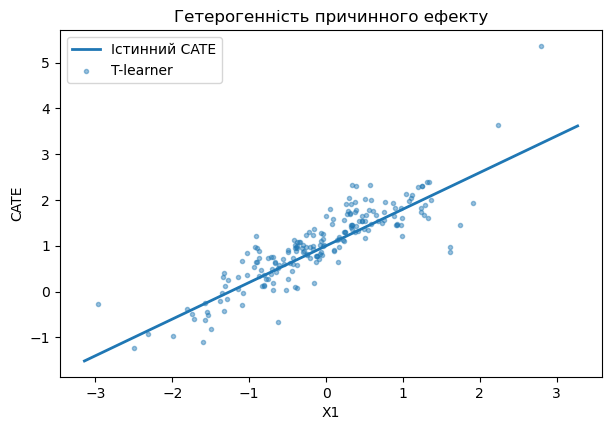

In [2]:
m0 = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=12,
    random_state=SEED, n_jobs=1
)
m1 = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=12,
    random_state=SEED+1, n_jobs=1
)
m0.fit(X[T==0],Y[T==0])
m1.fit(X[T==1],Y[T==1])
cate_t = m1.predict(X)-m0.predict(X)

print("T-learner ATE:", round(float(cate_t.mean()),3))
print("CATE RMSE (лише синтетичний контроль):",
      round(float(np.sqrt(mean_squared_error(tau_true,cate_t))),3))

fig,ax=plt.subplots(figsize=(7,4.5))
idx=np.argsort(x1)
ax.plot(x1[idx],tau_true[idx],label="Істинний CATE",linewidth=2)
ax.scatter(x1[::12],cate_t[::12],s=9,alpha=.45,label="T-learner")
ax.set(xlabel="X1",ylabel="CATE",title="Гетерогенність причинного ефекту")
ax.legend()
plt.show()


## 8.2. AIPW із cross-fitting

Оцінимо propensity та регресії результату на *інших* фолдах і побудуємо позавибіркові прогнози для кожного спостереження. Це демонструє коректну організацію nuisance-оцінювання.

*Важливо:* обрізання propensity тут є числовою стабілізацією; воно може змінювати оцінку і не замінює аудит позитивності.


In [3]:
kf=KFold(n_splits=3,shuffle=True,random_state=SEED)
e_hat=np.empty(n)
mu0_hat=np.empty(n)
mu1_hat=np.empty(n)

for train_idx,test_idx in kf.split(X):
    Xt, Xv=X[train_idx],X[test_idx]
    Tt,Yt=T[train_idx],Y[train_idx]
    ps=RandomForestClassifier(
        n_estimators=80,min_samples_leaf=20,
        random_state=SEED,n_jobs=1
    )
    ps.fit(Xt,Tt)
    e_hat[test_idx]=ps.predict_proba(Xv)[:,1]

    for treatment, target in [(0,mu0_hat),(1,mu1_hat)]:
        reg=RandomForestRegressor(
            n_estimators=80,min_samples_leaf=15,
            random_state=SEED+treatment,n_jobs=1
        )
        reg.fit(Xt[Tt==treatment],Yt[Tt==treatment])
        target[test_idx]=reg.predict(Xv)

e_safe=np.clip(e_hat,0.05,0.95)
aipw_scores=(mu1_hat-mu0_hat
             +T*(Y-mu1_hat)/e_safe
             -(1-T)*(Y-mu0_hat)/(1-e_safe))
ate_aipw=float(aipw_scores.mean())
se_aipw=float(aipw_scores.std(ddof=1)/np.sqrt(n))
ci=(ate_aipw-1.96*se_aipw,ate_aipw+1.96*se_aipw)
print("AIPW ATE:",round(ate_aipw,3))
print("Ілюстративний 95% Wald CI:",tuple(round(v,3) for v in ci))
print("Справжній ATE (генератор):",round(float(tau_true.mean()),3))
print("Частка обрізаних propensity:",
      round(float(np.mean(e_hat!=e_safe)),3))


AIPW ATE: 1.064
Ілюстративний 95% Wald CI: (0.956, 1.172)
Справжній ATE (генератор): 0.982
Частка обрізаних propensity: 0.0


Цей інтервал ілюструє впливову-функційну стандартну похибку на основі AIPW-балів за незалежних однаково розподілених спостережень та належних умов для nuisance-моделей. Він не враховує кластеризацію, часову залежність, невиміряне змішування або помилки специфікації причинного графа.

## 8.3. Частково лінійний DML

Для порівняння застосуємо ортогоналізацію результату та втручання. Через задану гетерогенність справжнього ефекту коефіцієнт частково лінійного DML *не слід автоматично трактувати як ATE*: параметр моделі за гетерогенності може бути зваженим середнім ефектів.


In [4]:
y_oof=np.empty(n)
t_oof=np.empty(n)
for train_idx,test_idx in kf.split(X):
    reg_y=RandomForestRegressor(
        n_estimators=80,min_samples_leaf=15,
        random_state=SEED+3,n_jobs=1
    )
    reg_t=RandomForestRegressor(
        n_estimators=80,min_samples_leaf=20,
        random_state=SEED+4,n_jobs=1
    )
    reg_y.fit(X[train_idx],Y[train_idx])
    reg_t.fit(X[train_idx],T[train_idx])
    y_oof[test_idx]=reg_y.predict(X[test_idx])
    t_oof[test_idx]=reg_t.predict(X[test_idx])

y_res=Y-y_oof
t_res=T-t_oof
theta_dml=float(np.dot(t_res,y_res)/np.dot(t_res,t_res))
print("Частково лінійний DML-коефіцієнт:",
      round(theta_dml,3))
print("AIPW ATE:",round(ate_aipw,3))
print("Істинний ATE:",round(float(tau_true.mean()),3))


Частково лінійний DML-коефіцієнт: 1.091
AIPW ATE: 1.064
Істинний ATE: 0.982


# 9. Валідація причинного ML-оцінювання

Якість прогнозу nuisance-моделей -- *не те саме*, що достовірність причинного ефекту. Науковий аудит має щонайменше п'ять рівнів.

| Рівень | Що перевіряємо | Що не доводимо |
|---|---|---|
| Причинна постановка | Втручання, результат, DAG, часовий порядок | Відсутність прихованого змішування |
| Ідентифікація | Backdoor, обмінність, консистентність | Що припущення істинні |
| Позитивність | Overlap, розподіл propensity, ваги | Що проблемних страт немає поза вибіркою |
| Статистичне оцінювання | Cross-fitting, стійкість nuisance, CI | Автоматичну причинну валідність |
| Гетерогенність | CATE за попередньо заданими підгрупами, повторні вибірки | Достовірність усіх знайдених підгруп |

## 9.1. Перекриття та ефективність ваг

Діагностика propensity має передувати інтерпретації IPW/AIPW. Екстремальні ваги можуть зумовлювати нестабільність навіть за великого $n$.


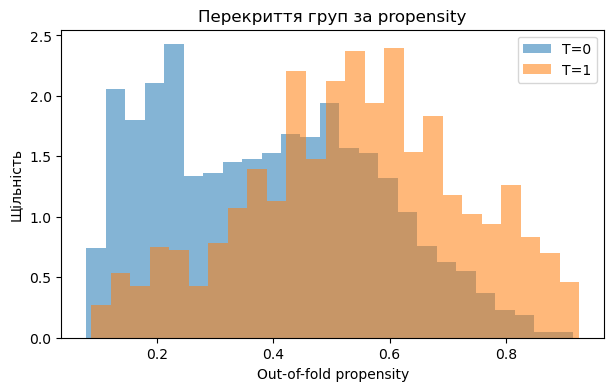

ESS за нестабілізованими IPW-вагами: 1829.0 із 2400
Квантилі ваг: [1.73 3.07 7.11]


In [5]:
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(e_hat[T==0],bins=25,alpha=.55,density=True,label="T=0")
ax.hist(e_hat[T==1],bins=25,alpha=.55,density=True,label="T=1")
ax.set(xlabel="Out-of-fold propensity",ylabel="Щільність",
       title="Перекриття груп за propensity")
ax.legend()
plt.show()

weights=T/e_safe+(1-T)/(1-e_safe)
ess=float(weights.sum()**2/np.sum(weights**2))
print("ESS за нестабілізованими IPW-вагами:",round(ess,1),
      "із",n)
print("Квантилі ваг:",np.round(np.quantile(weights,[.5,.9,.99]),2))


## 9.2. Висновок про гетерогенність

Порівняння підгруп, *обраних після перегляду тих самих даних*, створює ризик множинного тестування й оптимістичної оцінки відмінностей. Потрібні заздалегідь визначені гіпотези, чесне розділення вибірок або незалежна перевірка.

Для CATE не існує універсального спостережуваного «правильного значення» на кожному об'єкті. Тому звичайна RMSE між $\hat\tau(X_i)$ і невідомим $Y_i(1)-Y_i(0)$ не може бути обчислена на реальних даних. У нашому прикладі вона доступна лише завдяки генератору.

# 10. Межі Causal ML

1. *Невиміряне змішування* не усувається складністю ML-моделі.
2. *Інтерференція* у мережевих даних може порушувати стандартні потенційні наслідки.
3. *Зсув домену* обмежує перенесення ATE/CATE на іншу популяцію.
4. *Порушення позитивності* може зробити окремі ефекти неоцінюваними.
5. *Складна модель* не гарантує інтерпретованості виявленої гетерогенності.
6. *Невизначеність* вимагає врахування структури вибірки та дизайну.

# 11. Перехід до дисертаційного дослідження

У ЛР6 створено *Causal Research Specification v0.6*. Для ЛР7 потрібно розширити його до *Causal Effect Estimation & Validation v0.7*:

1. Зафіксувати estimand (ATE, ATT, CATE) та цільову популяцію.
2. Визначити причинні припущення й набір коригування.
3. Описати nuisance-моделі та їхні діагностики.
4. Вибрати оцінювач (IPW, AIPW, meta-learner, DML тощо).
5. Передбачити cross-fitting і аудит overlap.
6. Запланувати оцінювання невизначеності й аналіз чутливості.
7. Обмежити наукове твердження доступними доказами.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Causal Specification<br/>v0.6") --> B("Estimand і<br/>ідентифікація")
 B --> C("Causal ML<br/>оцінювання")
 C --> D("Overlap і<br/>невизначеність")
 D --> E("Effect Evidence<br/>v0.7")
```

# Контрольні питання

1. Чим ATE відрізняється від CATE?
2. Чому CATE не дорівнює індивідуальному контрфактуальному ефекту?
3. Що вимірює propensity score?
4. Яка роль позитивності для IPW?
5. Виведіть інтуїцію двічі стійкого AIPW.
6. Що означає double robustness, а чого не означає?
7. Як працюють S-learner і T-learner?
8. Чим причинний ліс відрізняється від Random Forest для прогнозу?
9. Навіщо потрібен cross-fitting?
10. Яку роль відіграє ортогоналізація в DML?
11. Чому частково лінійний DML-коефіцієнт за гетерогенності не обов'язково є ATE?
12. Чому точна nuisance-модель не доводить причинності?
13. Як перевіряють overlap і стабільність ваг?
14. Чому в реальних даних не можна напряму обчислити RMSE для індивідуальних ефектів?
15. Які припущення є найуразливішими у Вашій дисертаційній тематиці?

# Висновки

Causal ML поєднує формально ідентифіковані причинні параметри з гнучкими статистичними моделями. Його переваги -- робота з нелінійністю, високовимірними коваріатами та гетерогенністю ефектів. Його межі визначаються не лише якістю алгоритму, а насамперед причинними припущеннями, позитивністю, дизайном дослідження та надійністю оцінювання.

# Література та ресурси

Основні джерела: [@hernan2020causal; @pearl2009causality; @peters2017elements; @hastie2009elements].

Додатково: [Causal Inference: What If](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/), [EconML documentation](https://www.pywhy.org/EconML/), [DoubleML documentation](https://docs.doubleml.org/).

::: {#refs}
:::
